# Step 4a (option 1) — Dolphin, inference only (no fine-tuning)

[ByteDance's Dolphin](https://github.com/bytedance/Dolphin) has no public
training/fine-tuning code or documented data format (only inference demos),
so it can't be adapted to our 4 classes the way DocLayout-YOLO and Docling
can. It's still useful as a **zero-shot baseline**: this notebook runs it
as-is on our annotated pages and saves its detected layout elements in the
same shape as our own `annotations_flat.csv`, so it can be compared
side-by-side against the fine-tuned detectors and against our manual
Labelbox ground truth.

To keep this faithful to how Dolphin actually works (rather than guessing
at its output format), this notebook clones the official repo and imports
its real `demo_layout.py` / `utils/utils.py` directly -- so the box
parsing, coordinate mapping, and visualization code is exactly ByteDance's,
not a reimplementation.

**Label vocabulary note**: Dolphin detects generic elements like `fig`
(any figure/diagram/plot -- it doesn't distinguish Plot vs Diagram the way
our subtype split does), `tab` (table), `equ` (equation/formula), `sec_0..5`
/ `sec` (headings), `list`, `code`, etc. When comparing against our own
classes, `fig` is the fair comparison point for our combined Plot+Diagram+
Figure_Mixed boxes, and `tab` for our Table.

**Folder layout this notebook expects:**
```
2026/
  My_code/
    step04_detection/
      01_dolphin_baseline/    <- this notebook lives here (clones Dolphin into vendor_dolphin/ alongside it)
  Pre-Pages-2Annotate/         <- ndjson export + topic image folders
  Outputs/
```

**Compute note**: Dolphin-v2 is a 3B-parameter vision-language model. A GPU
is strongly recommended -- CPU inference will work but is slow (expect
tens of seconds per page). The model download below is ~6GB.


In [1]:
# Locate the project from either the project root or a notebook directory.
import os
import sys
from pathlib import Path
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "Pre-Pages-2Annotate").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "My_code"))
from annotation_inputs import latest_annotation_export, annotated_image_paths, build_image_index
os.chdir(PROJECT_ROOT / 'My_code/step04_detection/01_dolphin_baseline')
%matplotlib inline
import os
import subprocess
import sys
from pathlib import Path

VENDOR_DIR = Path("./vendor_dolphin")
MODEL_DIR = Path("./hf_model")

if not VENDOR_DIR.exists():
    print("Cloning bytedance/Dolphin (MIT licensed) -- reusing its real parsing code...")
    subprocess.run(["git", "clone", "--depth", "1",
                     "https://github.com/bytedance/Dolphin.git", str(VENDOR_DIR)], check=True)
else:
    print(f"{VENDOR_DIR} already present, skipping clone.")

sys.path.insert(0, str(VENDOR_DIR.resolve()))
print("Ready.")


vendor_dolphin already present, skipping clone.
Ready.


## Install dependencies

Only the packages actually needed for layout detection (skipping the
repo's training-only extras like `deepspeed`, `decord`, `torchcodec`).


In [2]:
%pip install -q torch transformers accelerate qwen_vl_utils pymupdf opencv-python-headless beautifulsoup4 huggingface_hub
print("Installed.")


Note: you may need to restart the kernel to use updated packages.
Installed.


## Download the model

One-time download of the official Dolphin-v2 checkpoint (~6GB) from
Hugging Face. Needs real internet access -- this is the cell to run on
your own machine (a sandboxed environment with restricted network access
won't be able to reach huggingface.co).


In [3]:
from huggingface_hub import snapshot_download

if not any(MODEL_DIR.glob("*")):
    print("Downloading ByteDance/Dolphin-v2 (this can take a while)...")
    snapshot_download(repo_id="ByteDance/Dolphin-v2", local_dir=str(MODEL_DIR))
else:
    print(f"{MODEL_DIR} already populated, skipping download.")


hf_model already populated, skipping download.


## Load the model and run it over our annotated pages

Uses `PortableDolphin` from `dolphin_runtime.py` to select CUDA (NVIDIA or
AMD ROCm), Apple MPS, Intel XPU, or CPU, in that order, based on availability
in the installed PyTorch build. The adapter inherits Dolphin's original
inference methods; layout processing and parsing still use `demo_layout.py`.
The selected device and precision are printed during loading. GPU availability
requires a compatible PyTorch installation and drivers. Model/operator support
and sufficient GPU memory are still required; inference errors are not silently
retried on CPU.

**Saved-result cache:** The inference cell reuses valid per-page JSON files in
`dolphin_results/output_json`, matched by image filename. Images newer than
their result are rerun. A fully cached test set skips model loading and
inference; partial runs resume only missing/invalid/outdated pages. With no
cached results, all test pages run from the beginning. The CSV is rebuilt
for the current test set. Keep image filenames unique; remove the relevant
saved JSON files to force a rerun (for example, after changing the model).


In [4]:
import demo_layout   # the cloned repo's own script, imported as a module
from dolphin_runtime import PortableDolphin


IMAGES_ROOT = Path("../../../Pre-Pages-2Annotate")
SAVE_DIR = Path("./dolphin_results")

# NOTE: demo_layout.py's own main() never calls setup_output_dirs() the way its
# sibling scripts (demo_page.py, demo_element.py) do -- it only creates SAVE_DIR
# itself, not the output_json/markdown/layout_visualization subfolders that
# save_outputs() writes into. Without this, save_outputs() crashes with
# FileNotFoundError on the very first page. Calling it explicitly here.
demo_layout.setup_output_dirs(str(SAVE_DIR))

assert IMAGES_ROOT.exists(), f"Images root not found at {IMAGES_ROOT.resolve()}"

# The inference cell loads the model only when uncached pages remain.


In [5]:
import csv
import json
from PIL import Image

# Select only labeled pages from the latest export across every topic folder.
ANNOTATIONS_ROOT = PROJECT_ROOT / "Pre-Pages-2Annotate" / "Exported_annotated_data"
NDJSON_PATH = latest_annotation_export(ANNOTATIONS_ROOT)
print(f"Annotation export: {NDJSON_PATH.name}")
image_paths = annotated_image_paths(NDJSON_PATH, IMAGES_ROOT)
if not image_paths:
    raise ValueError("No locally available labeled images found; check the export and IMAGES_ROOT.")


def read_layout_result(json_path):
    """Read and validate the fields needed by the CSV export."""
    with open(json_path) as f:
        elements = json.load(f)
    if not isinstance(elements, list):
        raise ValueError("Expected a list of layout elements")
    for el in elements:
        if not isinstance(el, dict):
            raise ValueError("Invalid layout element")
        bbox = el.get("bbox")
        if not isinstance(bbox, list) or len(bbox) != 4 or not all(
            isinstance(v, (int, float)) for v in bbox
        ):
            raise ValueError("Invalid bounding box")
        if not isinstance(el.get("label"), str) or "reading_order" not in el:
            raise ValueError("Missing label or reading order")
        tags = el.get("tags", [])
        if not isinstance(tags, list) or not all(isinstance(tag, str) for tag in tags):
            raise ValueError("Invalid tags")
    return elements


results = {}
pending_paths = []
for img_path in image_paths:
    json_path = SAVE_DIR / "output_json" / f"{img_path.stem}.json"
    try:
        # Existing results are matched by image filename. A newer input image
        # invalidates its saved result so edited pages are inferred again.
        if json_path.stat().st_mtime_ns < img_path.stat().st_mtime_ns:
            raise ValueError("Input image is newer than its cached result")
        results[img_path] = read_layout_result(json_path)
    except (OSError, ValueError, TypeError):
        pending_paths.append(img_path)

print(f"Cached pages: {len(results)}/{len(image_paths)}")
if not pending_paths:
    print("All test pages have saved results; skipping model loading and inference.")
else:
    print(f"Running Dolphin on {len(pending_paths)} uncached page(s)...")
    if "model" not in globals():
        model = PortableDolphin(str(MODEL_DIR))
        print(f"Model loaded on {model.model.device}.")
    for i, img_path in enumerate(pending_paths):
        print(f"[{i+1}/{len(pending_paths)}] {img_path.name}")
        try:
            demo_layout.process_layout(str(img_path), model, str(SAVE_DIR))
            json_path = SAVE_DIR / "output_json" / f"{img_path.stem}.json"
            results[img_path] = read_layout_result(json_path)
        except Exception as e:
            print(f"  -> error: {e}")
            continue

# Rebuild the CSV from cached + new results for the current test set only.
csv_rows = []
for img_path in image_paths:
    for el in results.get(img_path, []):
        x1, y1, x2, y2 = el["bbox"]
        csv_rows.append({
            "image": img_path.name, "dolphin_label": el["label"],
            "left": x1, "top": y1, "width": x2 - x1, "height": y2 - y1,
            "reading_order": el["reading_order"], "tags": ";".join(el.get("tags", [])),
        })

csv_path = SAVE_DIR / "dolphin_flat.csv"
with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["image", "dolphin_label", "left", "top",
                                            "width", "height", "reading_order", "tags"])
    writer.writeheader()
    writer.writerows(csv_rows)

print(f"\nSaved {len(csv_rows)} detected elements to {csv_path}")
if len(results) < len(image_paths):
    print(f"Incomplete run: {len(image_paths) - len(results)} page(s) failed; rerun to retry them.")


The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


Annotation export: Export  project - STEPS-Paper-Annotation - 9_23_2026.ndjson
Cached pages: 0/267
Running Dolphin on 267 uncached page(s)...
Loading Dolphin on mps (torch.float32)...


`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Model loaded on mps:0.
[1/267] A-comprehensive-review-on-microbial-fuel-cell-technologies_2019_Journal-of-C_page_0001.png
Parsing layout and reading order...
[2/267] A-comprehensive-review-on-microbial-fuel-cell-technologies_2019_Journal-of-C_page_0002.png
Parsing layout and reading order...
[3/267] A-comprehensive-review-on-microbial-fuel-cell-technologies_2019_Journal-of-C_page_0003.png
Parsing layout and reading order...
[4/267] A-comprehensive-review-on-microbial-fuel-cell-technologies_2019_Journal-of-C_page_0004.png
Parsing layout and reading order...
[5/267] A-comprehensive-review-on-microbial-fuel-cell-technologies_2019_Journal-of-C_page_0005.png
Parsing layout and reading order...
[6/267] A-comprehensive-review-on-microbial-fuel-cell-technologies_2019_Journal-of-C_page_0006.png
Parsing layout and reading order...
[7/267] A-comprehensive-review-on-microbial-fuel-cell-technologies_2019_Journal-of-C_page_0007.png
Parsing layout and reading order...
[8/267] A-comprehensive-review-o

## Preview a few pages with Dolphin's detected boxes

`demo_layout.py`'s own `save_outputs()` already draws and saves a
visualization per page -- just displaying a few of those here.


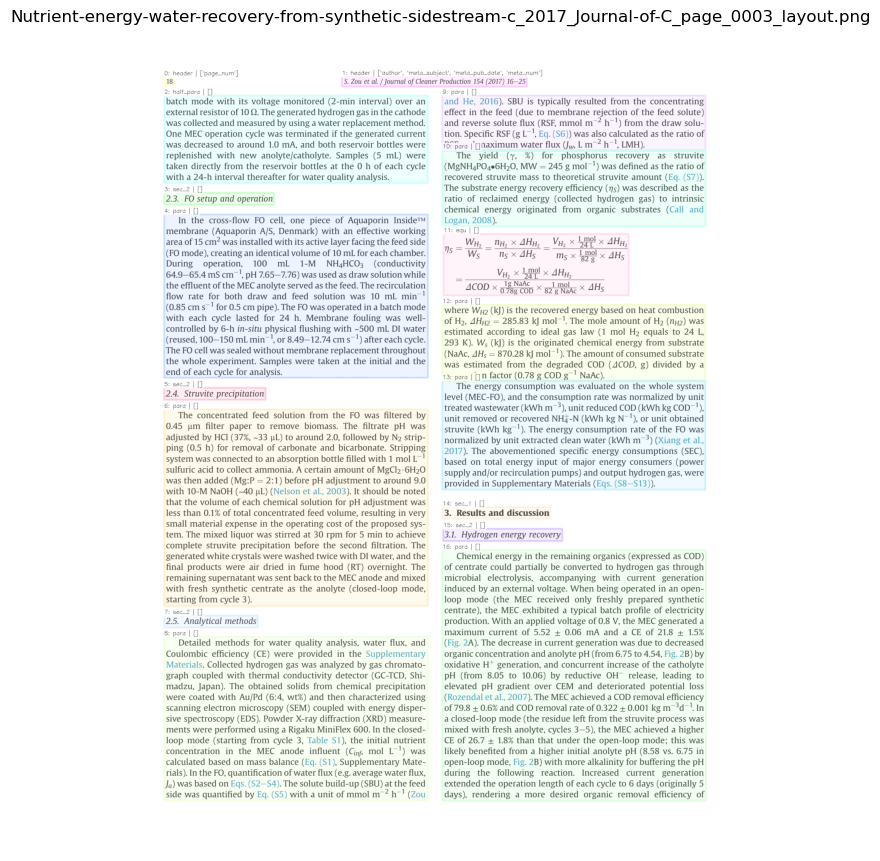

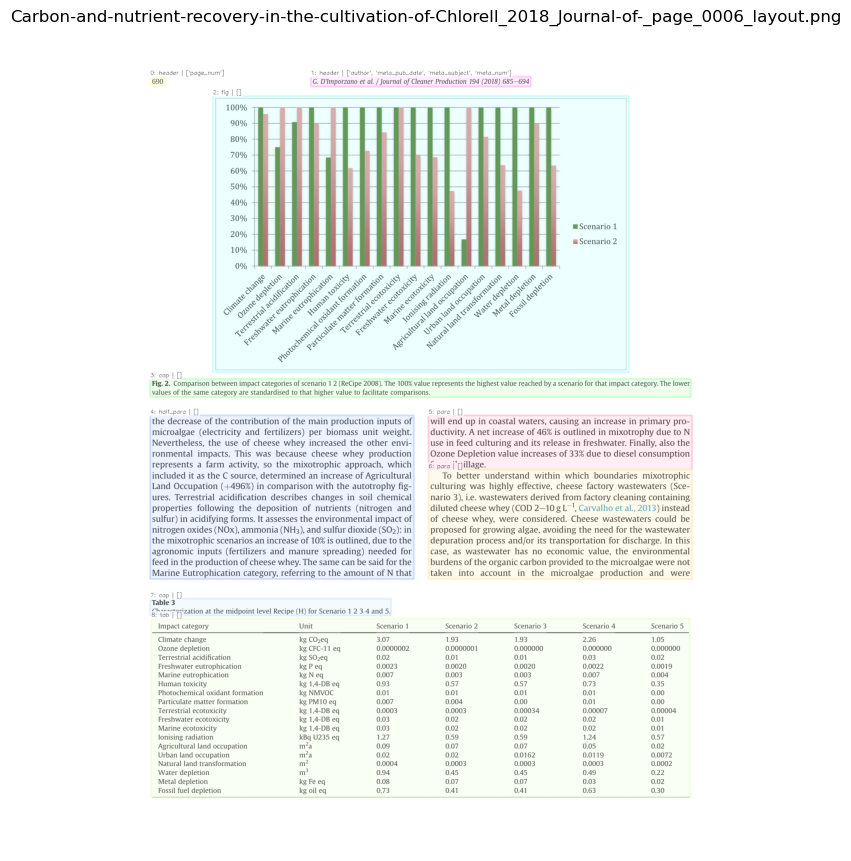

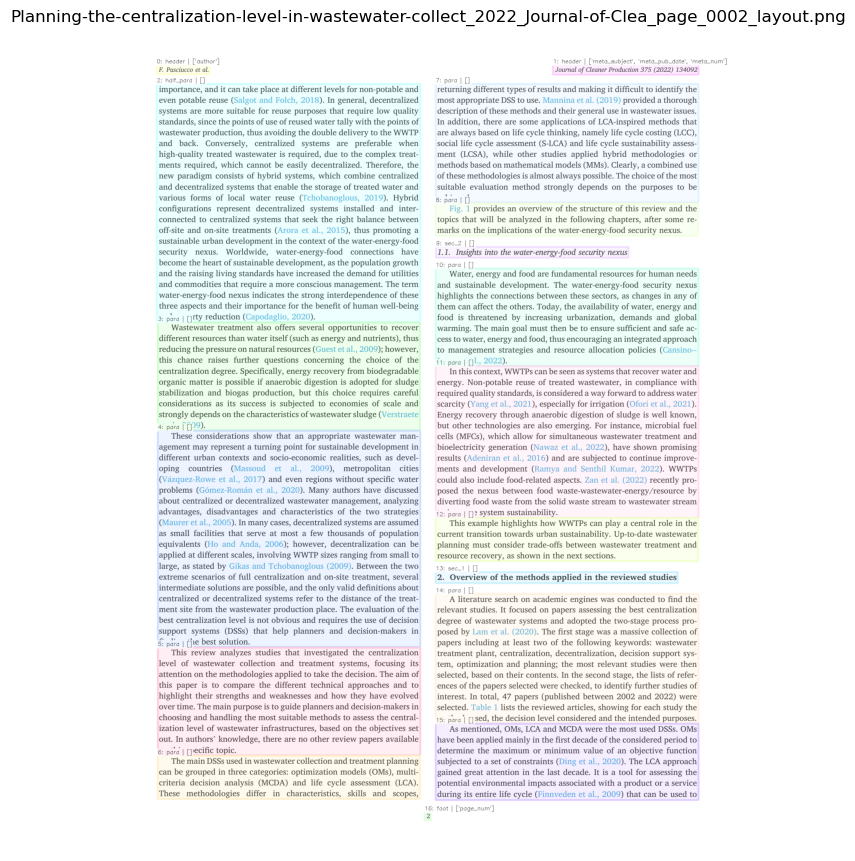

In [6]:
import random
import matplotlib.pyplot as plt

vis_dir = SAVE_DIR / "layout_visualization"
vis_files = sorted(vis_dir.glob("*.png")) if vis_dir.exists() else []

for vis_path in random.sample(vis_files, min(3, len(vis_files))):
    img = Image.open(vis_path)
    plt.figure(figsize=(8, 8 * img.size[1] / img.size[0]))
    plt.imshow(img)
    plt.axis("off")
    plt.title(vis_path.name)
    plt.show()


## First 20 detected figures

Crops saved `fig` detections from the current test pages, ordered by filename
and then reading order. Uses cached JSON results without running inference.


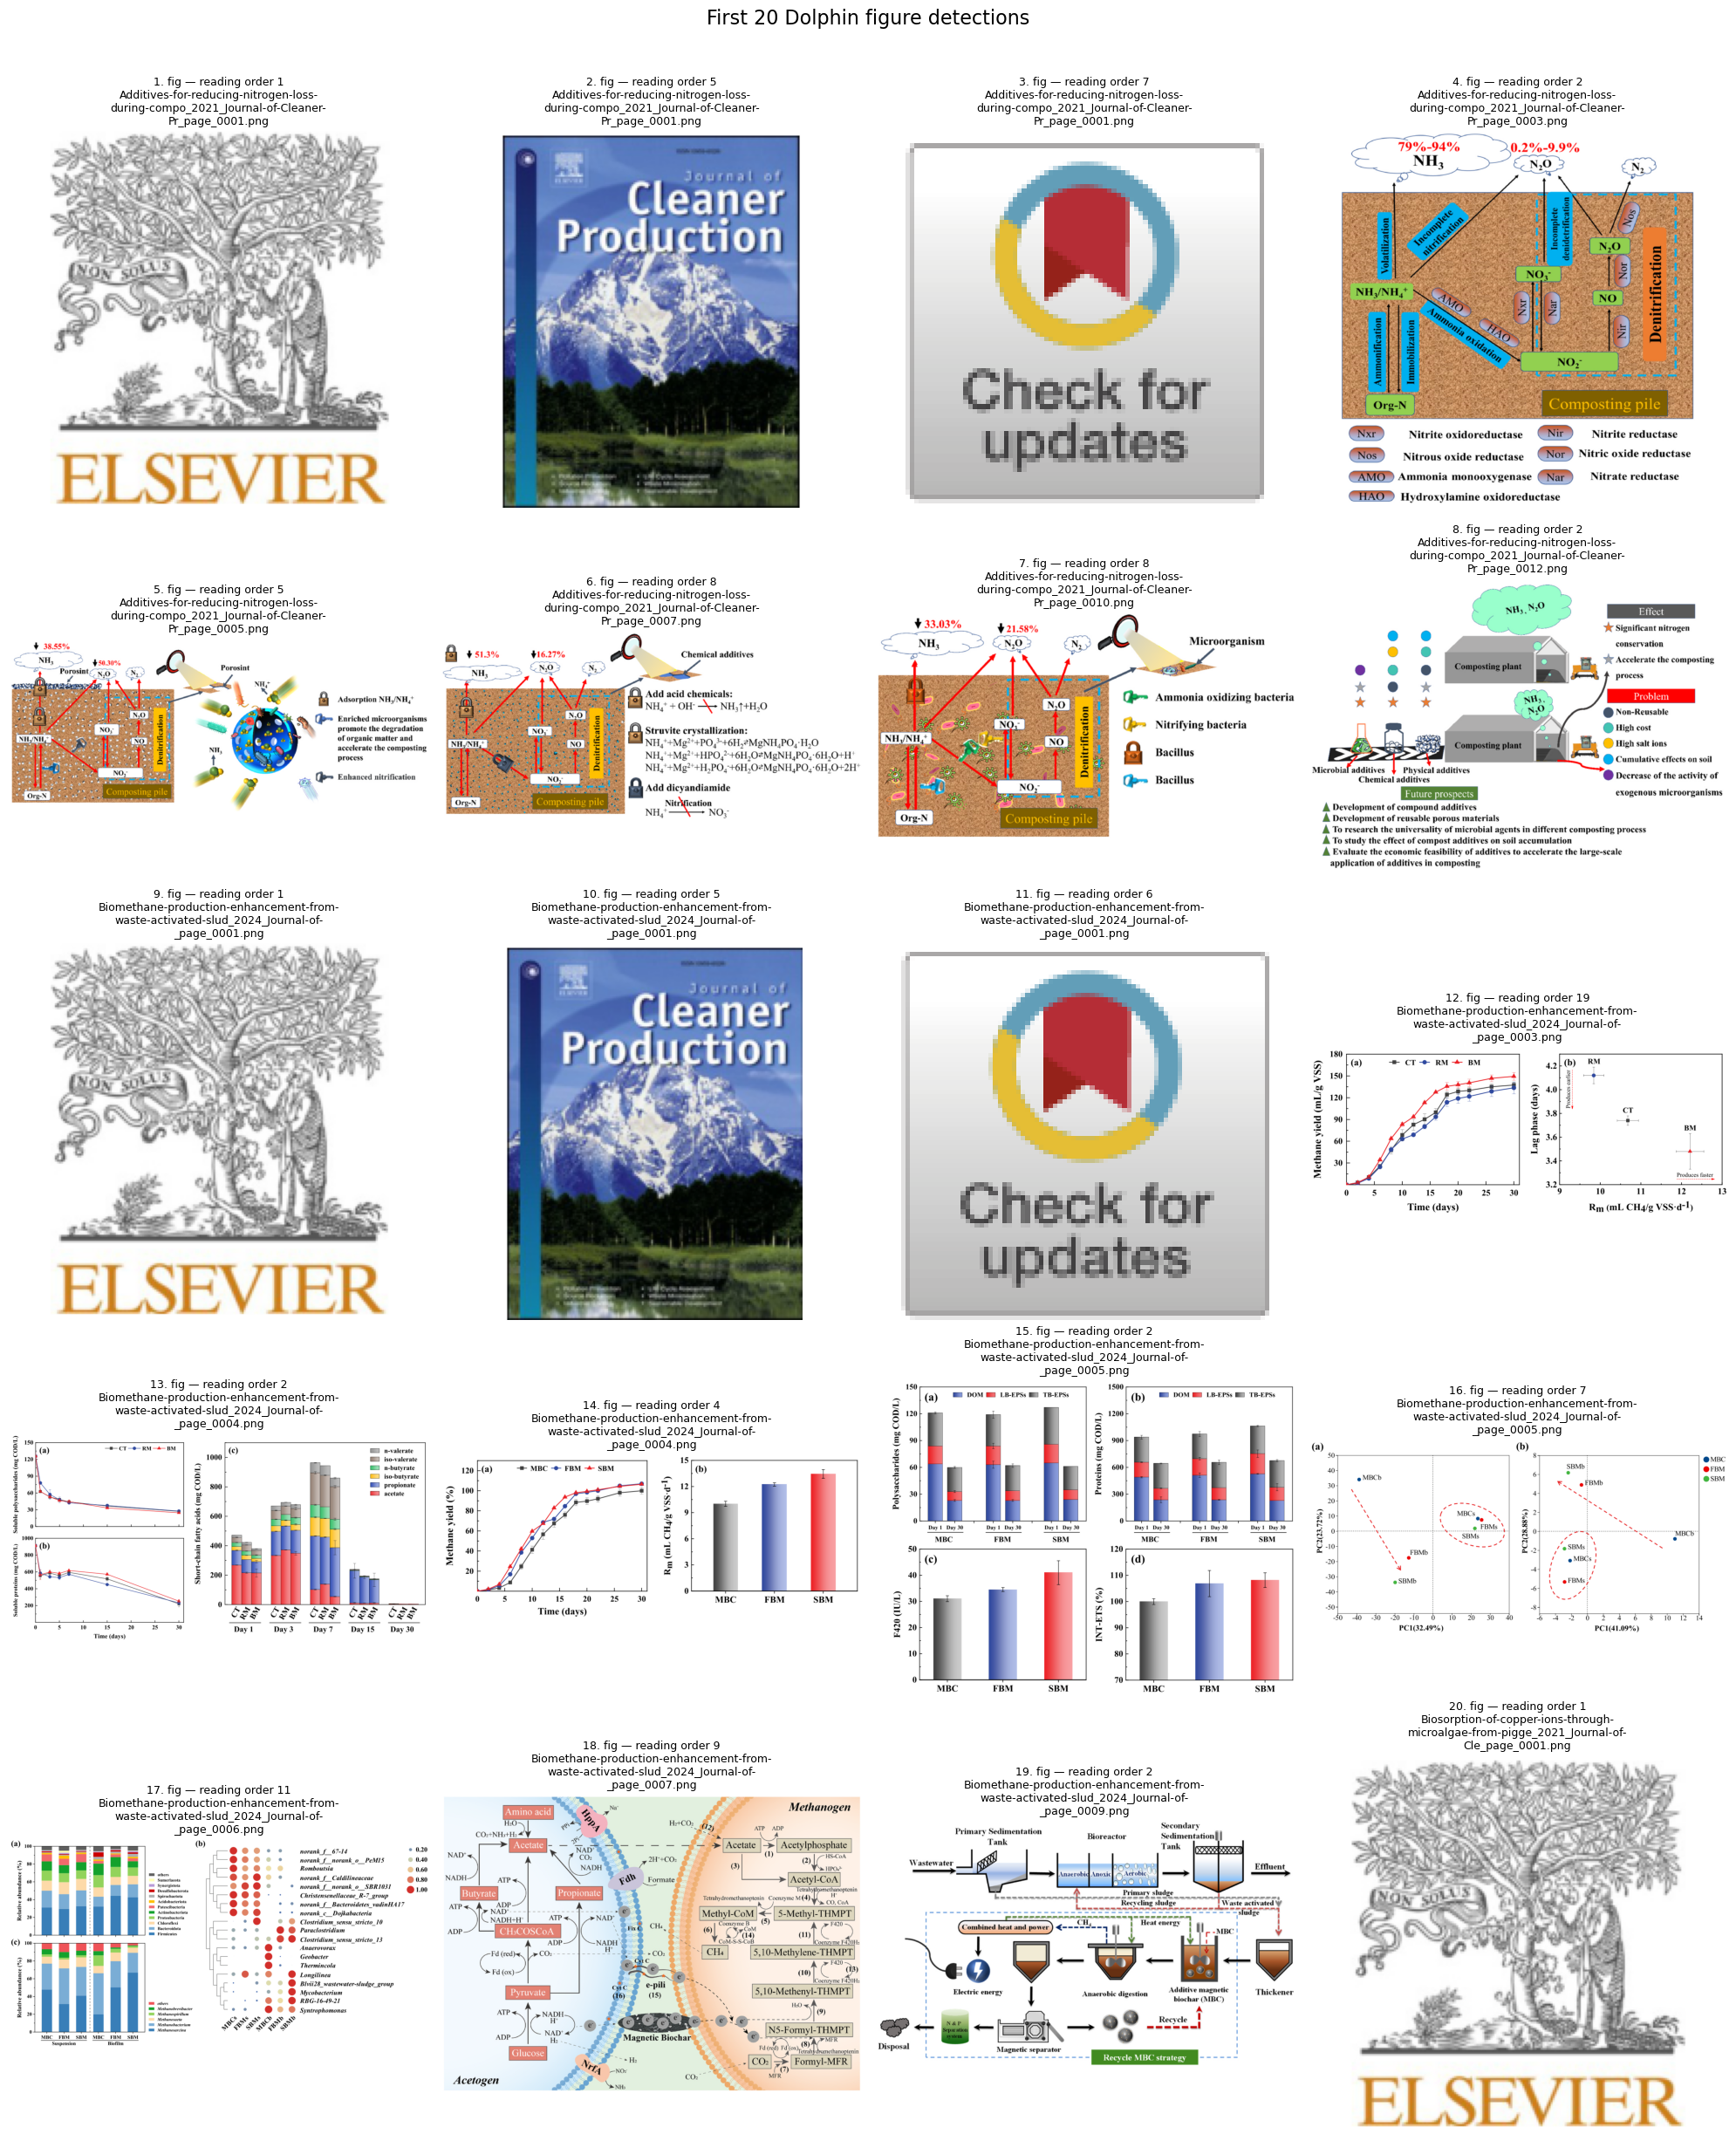

In [7]:
import json
import math
import textwrap
from PIL import Image
import matplotlib.pyplot as plt

# Use saved results only: first by test-page filename, then reading order.
figure_crops = []
for img_path in sorted(image_paths):
    result_path = SAVE_DIR / "output_json" / f"{img_path.stem}.json"
    if not result_path.exists():
        continue
    with open(result_path) as f:
        page_elements = json.load(f)
    figures = sorted(
        (el for el in page_elements if el.get("label") == "fig"),
        key=lambda el: el.get("reading_order", 0),
    )
    if not figures:
        continue
    with Image.open(img_path) as page:
        for el in figures:
            x1, y1, x2, y2 = el["bbox"]
            box = (max(0, math.floor(x1)), max(0, math.floor(y1)),
                   min(page.width, math.ceil(x2)), min(page.height, math.ceil(y2)))
            if box[2] <= box[0] or box[3] <= box[1]:
                continue
            figure_crops.append((page.crop(box).convert("RGB"), img_path.name,
                                 el.get("reading_order", 0)))
            if len(figure_crops) == 20:
                break
    if len(figure_crops) == 20:
        break

if not figure_crops:
    print("No saved 'fig' detections found for the current test set.")
else:
    ncols = 4
    nrows = math.ceil(len(figure_crops) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for index, (ax, (crop, filename, order)) in enumerate(
        zip(axes.flat, figure_crops), start=1
    ):
        ax.imshow(crop)
        ax.set_title(f"{index}. fig — reading order {order}\n"
                     + textwrap.fill(filename, width=42), fontsize=9)
    fig.suptitle(f"First {len(figure_crops)} Dolphin figure detections", fontsize=16)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


## Class distribution vs. our own labels

A first-glance comparison: how many `fig` / `tab` elements did Dolphin
find vs. our manual Plot+Diagram+Figure_Mixed / Table counts? This isn't a
proper precision/recall comparison (that needs IoU matching against our
ground-truth boxes, worth building once we have both detectors' outputs
side by side) -- just a sanity check that Dolphin is in the right
ballpark before investing in that.


dolphin_label
reference    1863
para         1260
header        572
sec_1         220
cap           213
sec_2         212
fig           203
foot          187
half_para     172
sec_3          91
fnote          85
tab            74
equ            67
anno           35
sec_0          20
list           11
catalogue       5
Name: count, dtype: int64


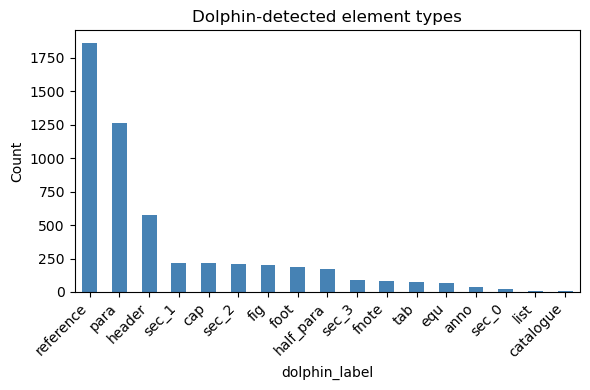

In [8]:
import pandas as pd

df = pd.read_csv(csv_path)
counts = df["dolphin_label"].value_counts()
print(counts)

counts.sort_values(ascending=False).plot(kind="bar", figsize=(6, 4), color="steelblue")
plt.ylabel("Count")
plt.title("Dolphin-detected element types")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
